# 05 · Knowledge base: raccolta, estrazione e divisione dei documenti

**Progetto:** HelpDesk AI · **Passo 3:** Generative AI

## Obiettivo di questo notebook

Il chatbot deve proporre istruzioni **basate su documentazione verificata, non inventate dal modello**. La tecnica è la **RAG** (*Retrieval-Augmented Generation*):

1. prima di rispondere, il sistema cerca nella knowledge base i pezzi di testo più pertinenti alla richiesta;
2. poi li passa all'LLM, che scrive la risposta usando solo quei pezzi e citando la fonte.

Perché la ricerca funzioni, i documenti vanno preparati: scaricati, trasformati in testo pulito e divisi in pezzi piccoli (*chunk*). È il lavoro di questo notebook. Il risultato è un file, `knowledge_base/chunks.jsonl`, che nel notebook `06` trasformeremo in un indice di ricerca.

```
fonti.csv -> download -> estrazione del testo -> pulizia -> divisione in chunk -> chunks.jsonl
```

Dobbiamo guardare il testo estratto per decidere come pulirlo: è un lavoro esplorativo, come l'EDA del notebook 01. L'app non userà queste funzioni: userà solo l'indice già pronto.

### Cosa faremo

1. Import e configurazione
2. Il catalogo delle fonti
3. Download dei documenti
4. Estrazione del testo
5. Pulizia
6. Divisione in chunk
7. Statistiche e controlli
8. Lettura esempi
9. Salvataggio
10. Riepilogo

## 1. Import e configurazione
Le novità rispetto ai notebook precedenti:

| Libreria | A cosa serve |
|---|---|
| `requests` | scaricare i documenti dal web |
| `pypdf` | estrarre il testo dai PDF, pagina per pagina |
| `langchain_text_splitters` | dividere il testo in chunk (`RecursiveCharacterTextSplitter`) |
| `re`, `html`, `unicodedata` | pulire il testo con espressioni regolari, entità HTML e normalizzazione dei caratteri |

**Perché `pypdf`?** È scritta solo in Python (si installa senza problemi anche su Windows) e ha una licenza permissiva.

In [1]:
from pathlib import Path
from collections import Counter
import json
import re
import html
import time
import logging
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from pypdf import PdfReader
from langchain_text_splitters import RecursiveCharacterTextSplitter

# pypdf segnala con molti avvisi i PDF non perfettamente conformi: mostriamo solo gli errori veri
logging.getLogger("pypdf").setLevel(logging.ERROR)

In [2]:
# --- Riproducibilità ---
RANDOM_STATE = 42

# --- Percorsi ---
PROJECT_DIR = Path("..")
KB_DIR = PROJECT_DIR / "knowledge_base"
CATALOGO_PATH = KB_DIR / "fonti.csv"
RAW_DIR = KB_DIR / "raw"                     # documenti scaricati (esclusi da Git)
CHUNKS_PATH = KB_DIR / "chunks.jsonl"        # risultato del notebook (escluso da Git)
RIEPILOGO_PATH = KB_DIR / "riepilogo_fonti.csv"
RAW_DIR.mkdir(parents=True, exist_ok=True)

# --- Parametri della pulizia e della divisione ---
MIN_CARATTERI_PAGINA = 100   # pagine più corte (copertine, pagine vuote) vengono scartate
CHUNK_SIZE = 1000            # lunghezza massima di un chunk, in caratteri
CHUNK_OVERLAP = 150          # caratteri ripetuti tra un chunk e il successivo
MIN_CARATTERI_CHUNK = 80     # chunk più corti (frammenti) vengono scartati

# --- Stile dei grafici ---
COLORE = "#2a78d6"
TESTO_SECONDARIO = "#52514e"
GRIGLIA = "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIGLIA,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRIGLIA,
    "xtick.color": TESTO_SECONDARIO,
    "ytick.color": TESTO_SECONDARIO,
})
pd.set_option("display.max_colwidth", 120)

## 2. Il catalogo delle fonti

Invece di scaricare i documenti a mano e metterli in una cartella, li elenchiamo in un catalogo (`knowledge_base/fonti.csv`). È una scelta che ripaga in quattro modi:

- **riproducibilità:** chiunque cloni il repository può ricostruire la knowledge base eseguendo questo notebook;
- **licenze:** per ogni fonte sappiamo chi l'ha pubblicata e con quale licenza;
- **citazioni:** il chatbot potrà indicare da quale documento viene un'istruzione, con il link;
- **filtri:** categoria e periferica diventano **metadati** dei chunk, utili nella ricerca.

| Colonna | Significato |
|---|---|
| `id` | nome breve e univoco, usato anche per il file scaricato |
| `titolo`, `editore` | cosa è e chi lo ha pubblicato |
| `tipo` | `pdf` (manuali) o `markdown` (articoli Microsoft) |
| `download` | `auto` se lo scarica il notebook, `manuale` se il sito non permette il download diretto |
| `url` / `url_citazione` | da dove scaricare / quale link mostrare all'utente |
| `lingua` | lingua del testo da tenere (`en` o `it`) |
| `licenza` | condizioni d'uso |
| `categoria` | categoria del classificatore a cui serve la fonte |
| `periferica` | per i manuali: il tipo di dispositivo |

### Le scelte sulle fonti

- **Articoli Microsoft:** vengono dal repository pubblico `MicrosoftDocs/SupportArticles-docs` su GitHub, con licenza **CC BY 4.0**: si possono usare citando la fonte. Li scarichiamo in **Markdown**, il formato originale, invece di estrarli dalle pagine web: niente menu, pubblicità o codice HTML da togliere.
- **Manuali delle periferiche:** sono pubblicati dai produttori o dal fornitore del servizio. Sono liberamente scaricabili ma **non ridistribuibili**: per questo `knowledge_base/raw/` è escluso da Git, e nel repository resta solo il catalogo con i link.
- **Ubuntu Server Guide:** l'ho inserita nella sinossi ma contiene istruzioni per chi amministra server Linux, per cui non sarebbe utile ad un utente che lavora allo sportello e l'ho rimossa.

In [3]:
catalogo = pd.read_csv(CATALOGO_PATH).fillna("")

# Controlli di id univoci, campi obbligatori pieni e valori ammessi
assert catalogo["id"].is_unique, "Ci sono id duplicati nel catalogo"
obbligatori = ["id", "titolo", "editore", "tipo", "download", "url", "lingua", "licenza", "categoria"]
vuoti = catalogo[obbligatori].eq("").sum()
assert vuoti.sum() == 0, f"Campi obbligatori vuoti:\n{vuoti[vuoti > 0]}"
assert catalogo["tipo"].isin(["pdf", "markdown"]).all(), "tipo deve essere 'pdf' o 'markdown'"
assert catalogo["download"].isin(["auto", "manuale"]).all(), "download deve essere 'auto' o 'manuale'"

print(f"Fonti nel catalogo: {len(catalogo)}\n")
display(pd.crosstab(catalogo["categoria"], catalogo["tipo"], margins=True, margins_name="totale"))
display(catalogo.loc[catalogo["tipo"] == "pdf", ["id", "editore", "periferica", "lingua", "download"]])

Fonti nel catalogo: 39



tipo,markdown,pdf,totale
categoria,,,
Access,8,0,8
Administrative rights,4,0,4
Hardware,9,12,21
Storage,6,0,6
totale,27,12,39


,id,editore,periferica,lingua,download
27,ingenico_ipp320,Ingenico,POS,en,auto
28,nexi_pos_ingenico_it,Nexi,POS,it,auto
29,pax_a920_it,PostFinance,POS,it,auto
30,wacom_stu,Wacom,pad di firma,en,auto
31,namirial_nt10,Namirial,pad di firma,en,auto
32,olivetti_mb2,Olivetti,stampante di sportello,en,auto
33,kyocera_ma5500ifx,Kyocera,stampante di rete,en,manuale
34,epson_wfm5899,Epson,stampante di rete,en,auto
35,lexmark_mx431,Lexmark,stampante di rete,en,auto
36,zebra_zd421,Zebra,stampante di etichette,en,auto


### Osservazioni (parte 2)
- **39 fonti**: 27 articoli Microsoft (CC BY 4.0) e 12 manuali di periferiche. Per categoria: Hardware 21, Access 8, Storage 6, Administrative rights 4.
- **Hardware ha più di metà delle fonti** perché tutte le periferiche di sportello rientrano in questa categoria che è anche la più grande del dataset (28,5% dei ticket).
- **Administrative rights è la categoria con meno documenti** (4 articoli) e manca Outlook, che nel notebook 02 era la parola più forte di questa categoria.
- **Restano senza documenti HR Support, Purchase, Internal Project e Miscellaneous**: richieste non tecniche o che l'utente non può risolvere da solo per cui il chatbot inoltra subito il ticket.

## 3. Download dei documenti
Per ogni fonte del catalogo, il notebook scarica il file in `knowledge_base/raw/` e lo chiama con l'`id` (es. `zebra_zd421.pdf`).

Accorgimenti:

| Accorgimento | Perché |
|---|---|
| se il file c'è già, non lo riscarica | possiamo rieseguire il notebook senza ripetere i download |
| `User-Agent` per simulare un browser | alcuni siti rifiutano le richieste che non sembrano arrivare da un browser |
| `timeout=60` | se un sito non risponde, non restiamo bloccati |
| controlliamo che un PDF inizi con `%PDF` | a volte il server restituisce una pagina HTML invece del file: senza controllo salveremmo un "PDF" che non lo è |
| una pausa di 1 secondo tra i download | per non sovraccaricare i siti |
| gli errori non fermano il notebook | se un sito è irraggiungibile, si prosegue con le altre fonti e si recupera il file a mano |

In [4]:
INTESTAZIONI = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) HelpDeskAI-Capstone"}


def percorso_file(fonte):
    estensione = ".pdf" if fonte["tipo"] == "pdf" else ".md"
    return RAW_DIR / f"{fonte['id']}{estensione}"


def scarica(fonte):
    # Scarica una fonte e restituisce una breve descrizione dell'esito
    destinazione = percorso_file(fonte)
    if destinazione.exists() and destinazione.stat().st_size > 0:
        return "già presente"
    if fonte["download"] == "manuale":
        return "da scaricare a mano"
    try:
        risposta = requests.get(fonte["url"], headers=INTESTAZIONI, timeout=60)
        risposta.raise_for_status()
    except requests.RequestException as errore:
        return f"errore: {type(errore).__name__}"
    finally:
        time.sleep(1)
    if fonte["tipo"] == "pdf" and not risposta.content.startswith(b"%PDF"):
        return "errore: il server non ha restituito un PDF"
    destinazione.write_bytes(risposta.content)
    return "scaricato"

In [5]:
%%time
esiti = []
for fonte in catalogo.to_dict("records"):
    esiti.append({"id": fonte["id"], "esito": scarica(fonte)})
esiti = pd.DataFrame(esiti)

print(esiti["esito"].value_counts().to_string(), "\n")

# Istruzioni per eventuali file da recuperare a mano
da_recuperare = catalogo.merge(esiti, on="id").query("esito != 'scaricato' and esito != 'già presente'")
for fonte in da_recuperare.to_dict("records"):
    print(f"- {fonte['id']} ({fonte['esito']})")
    print(f"  apri {fonte['url']}")
    print(f"  scarica '{fonte['titolo']}' e salvalo come {percorso_file(fonte).resolve()}\n")

esito
già presente    39 

CPU times: total: 15.6 ms
Wall time: 13 ms


### Osservazioni (parte 3)
- Tutte le 39 fonti sono disponibili: 38 scaricate in automatico al primo tentativo, Kyocera recuperato a mano (il sito non ha un link diretto al PDF).
- Rieseguendo il notebook i file già presenti non vengono riscaricati.

## 4. Estrazione del testo

Lavoriamo per unità: per i PDF usiamo la pagina mentre per gli articoli Markdown una sezione. Questo ci serve per indicare da quale pagina o sezione viene ogni *chunk*.

### 4.1 PDF

`PdfReader` legge il file e `extract_text()` restituisce il testo di ogni pagina. Una pagina che contiene solo immagini (es. scansioni) restituisce un testo vuoto: per quelle è necessario il riconoscimento ottico dei caratteri che qui però non usiamo. Contiamo quante sono, per accorgerci se un manuale è stato scansionato.

In [6]:
def estrai_pdf(percorso):
    # Restituisce una lista con il testo di ogni pagina (stringa vuota se la pagina non ha testo)
    lettore = PdfReader(percorso)
    return [pagina.extract_text() or "" for pagina in lettore.pages]

### 4.2 Markdown

Gli articoli Microsoft iniziano con un'intestazione **YAML** (*front matter*, tra due righe `---`) con il titolo e altri dati per il sito, e contengono commenti `<!-- ... -->` per i redattori. Per prima cosa li rimuoviamo, poi dividiamo il testo nelle sezioni che iniziano con `#`, `##` o `###`.

Dentro i blocchi di codice (tra due righe ` ``` `) una riga che inizia con `#` è un **commento** di PowerShell, non un titolo. Per questo la funzione tiene traccia di quando si trova dentro un blocco di codice.

In [7]:
def dividi_markdown(testo):
    # Toglie intestazione YAML e commenti, poi divide in sezioni: lista di (titolo della sezione, testo)
    testo = re.sub(r"\A---\n.*?\n---\n", "", testo, flags=re.S)
    testo = re.sub(r"<!--.*?-->", "", testo, flags=re.S)

    sezioni, titolo, righe, dentro_codice = [], "", [], False
    for riga in testo.splitlines():
        if riga.strip().startswith("```"):
            dentro_codice = not dentro_codice
        if not dentro_codice and re.match(r"^#{1,3} ", riga):
            if "".join(righe).strip():
                sezioni.append((titolo, "\n".join(righe)))
            titolo, righe = riga.lstrip("#").strip(), []
        else:
            righe.append(riga)
    if "".join(righe).strip():
        sezioni.append((titolo, "\n".join(righe)))
    return sezioni

### 4.3 Estrazione delle fonti
Per ogni fonte creiamo le unità ed i relativi metadati.

In [8]:
%%time
unita = []      # una riga per pagina (PDF) o per sezione (Markdown)
mancanti = []

for fonte in catalogo.to_dict("records"):
    percorso = percorso_file(fonte)
    if not percorso.exists():
        mancanti.append(fonte["id"])
        continue
    if fonte["tipo"] == "pdf":
        try:
            pagine = estrai_pdf(percorso)
        except Exception as errore:          # per PDF danneggiato o protetto
            print(f"Impossibile leggere {percorso.name}: {errore}")
            mancanti.append(fonte["id"])
            continue
        for numero, testo in enumerate(pagine, start=1):
            unita.append({"id_fonte": fonte["id"], "pagina": numero, "sezione": "", "testo": testo})
    else:
        for titolo_sezione, testo in dividi_markdown(percorso.read_text(encoding="utf-8")):
            unita.append({"id_fonte": fonte["id"], "pagina": None, "sezione": titolo_sezione, "testo": testo})

unita = pd.DataFrame(unita)
unita["caratteri"] = unita["testo"].str.len()

print(f"Fonti estratte: {unita['id_fonte'].nunique()} su {len(catalogo)}"
      + (f" | mancanti: {', '.join(mancanti)}" if mancanti else ""))
print(f"Unità estratte: {len(unita)} (pagine PDF: {unita['pagina'].notna().sum()}, "
      f"sezioni Markdown: {unita['pagina'].isna().sum()})")

Fonti estratte: 39 su 39
Unità estratte: 1976 (pagine PDF: 1770, sezioni Markdown: 206)
CPU times: total: 50 s
Wall time: 51.6 s


In [9]:
# Conteggio pagine di ogni PDF e quante sono senza testo?
pagine_pdf = unita[unita["pagina"].notna()]
controllo_pdf = pagine_pdf.groupby("id_fonte").agg(
    pagine=("pagina", "size"),
    pagine_senza_testo=("caratteri", lambda c: int((c == 0).sum())),
    caratteri_medi=("caratteri", "mean"),
).round(0).sort_values("pagine", ascending=False)
display(controllo_pdf)

,pagine,pagine_senza_testo,caratteri_medi
id_fonte,,,
kyocera_ma5500ifx,579,1,1266.0
epson_wfm5899,415,2,1267.0
zebra_zd421,352,0,1054.0
lexmark_mx431,289,0,1079.0
viewsonic_va2432,44,1,1085.0
jetscan_ifx_i100,32,0,1204.0
olivetti_mb2,28,2,896.0
namirial_nt10,9,0,454.0
nexi_pos_ingenico_it,8,0,1661.0


### Osservazioni (parte 4)
Con il 92% del testo, i manuali delle stampanti di rete rischiano di essere richiamati anche quando la domanda si riferisce altro. Inoltre, una richiesta generica come "la carta si è inceppata" potrebbe restituire Kyocera o Epson invece della stampante di sportello Olivetti. Possibili rimedi da valutare nel prossimo notebook: aggiungere titolo e periferica al testo dei chunk, filtrare per periferica quando è nota dalla conversazione, limitare il numero di chunk per fonte nei risultati.

## 5. Pulizia
Guardiamo qualche pagina "grezza" per capire cosa può essere rimosso e poi procediamo alla pulizia

In [10]:
def mostra_pagina(id_fonte, pagina, caratteri=1500):
    # Stampa il testo grezzo di una pagina di un PDF
    riga = pagine_pdf[(pagine_pdf["id_fonte"] == id_fonte) & (pagine_pdf["pagina"] == pagina)].iloc[0]
    print(f"=== {id_fonte} · pagina {pagina} ({riga['caratteri']} caratteri)\n")
    print(riga["testo"][:caratteri], "\n")


# Prendiamo 3 pagine scelte a caso da tre manuali diversi, almeno 300 caratteri.
SEME_ESEMPI = RANDOM_STATE
candidate = pagine_pdf[pagine_pdf["caratteri"] >= 300]
una_per_fonte = candidate.groupby("id_fonte").sample(1, random_state=SEME_ESEMPI)
scelte = una_per_fonte.sample(min(3, len(una_per_fonte)), random_state=SEME_ESEMPI)
for riga in scelte.to_dict("records"):
    mostra_pagina(riga["id_fonte"], int(riga["pagina"]))

esempio = scelte.iloc[0]   # la useremo per il confronto tra prima e dopo la pulizia

=== wacom_stu · pagina 2 (1555 caratteri)

Administrator’s Guide to Setting Up Wacom STU Display  
 
Wacom GSDT Page 2 of 6 May 2013 
 
Customization 
 
The Wacom STU Display application consists of the following portions: 
1. Windows Service Wacom STU Display (wgssStudSvc.exe) 
2. Windows Control Panel Wacom STU Display (wgssSTUDCPL.exe, wgssSTUDCPL.dll) 
3. Folders containing sample images for each supported tablet 
 
The Wacom STU Display Control Panel can be used to customize STU Display settings. 
 
Changing settings requires clicking the Change button. That will initiate the UAC prompt for elevated 
privileges. If you are a member of the local administrator group you should simply have to select 
continue, otherwise you need to enter the administrative password. 
Note: the control panel cannot be used to select an image folder on a network or removable drives, 
because that requires the Wacom STU Display Service to run under a user with (domain) network 
credentials. Please see t

### 5.1 Problemi derivanti da estrazione del testo da PDF

| Problema | Esempio | Soluzione |
|---|---|---|
| **legature** e caratteri tipografici | `ﬁ` invece di `fi` | normalizzazione Unicode **NFKC** |
| **parole spezzate** a fine riga | `connec-` / `tion` | riunirle quando la riga finisce con un trattino |
| **intestazioni e piè di pagina** | titolo del manuale e numero di pagina ripetuti su ogni pagina | togliere le righe che compaiono **in cima o in fondo** ad almeno metà delle pagine dello stesso documento |
| **numeri di pagina** | `12`, `Page 12 of 40` | togliere le righe fatte solo di un numero di pagina |
| **indici** | `Clearing jams ........ 227`, `Copying ........ 5-15` | togliere le righe con puntini seguiti da un numero di pagina; scartare le pagine che sono quasi tutte indice |
| **spazi** in eccesso | righe vuote multiple | ridurli |
| **simboli dei font** | i pallini degli elenchi diventano caratteri illeggibili come `` | sostituirli con un trattino |

Alle righe dell'indice dedichiamo particolare attenzione perché contengono proprio le parole delle domande ma nessuna istruzione. Se le lasciassimo la ricerca le troverebbe spesso e l'LLM riceverebbe un elenco di titoli invece di una procedura.

**Perché confrontare la "forma" delle righe e solo quelle brevi in cima e in fondo?** Molti piè di pagina cambiano solo per il numero ("Page 2 of 6", "Page 3 of 6"): sostituendo i numeri con `#` diventano la stessa forma. Limitandoci alle righe brevi ai bordi della pagina, dove stanno intestazioni e piè di pagina, evitiamo di togliere righe di testo che differiscono solo per un numero.

In [11]:
# Numero di pagina da solo
RIGA_NUMERO_PAGINA = re.compile(r"^\s*(page|pagina|pag\.)?\s*\d{1,4}(\s*(of|di|/|-|–)\s*\d{1,4})?\s*$", re.I)
# Voce di indice: puntini seguiti da un numero di pagina
RIGA_INDICE = re.compile(r"(\.\s?){4,}\s*(\d{1,4}([-–.]\d{1,4})?|[ivxlc]{1,6})\s*$", re.I)

def quota_indice(testo):
    # Quota delle righe della pagina che sono voci di un indice
    righe = [riga.strip() for riga in testo.splitlines() if riga.strip()]
    return sum(bool(RIGA_INDICE.search(riga)) for riga in righe) / len(righe) if righe else 0.0

def forma(riga):
    # La composizione di una riga: i numeri diventano #
    return re.sub(r"\d+", "#", riga.strip())

def righe_ripetute(testi_pagine, quota=0.5, righe_bordo=2, max_caratteri=60):
    # Intestazioni e piè di pagina: forme di riga brevi che compaiono tra le prime o le ultime righe di almeno metà delle pagine
    conteggio = Counter()
    for testo in testi_pagine:
        righe = [riga.strip() for riga in testo.splitlines() if riga.strip()]
        bordo = [riga for riga in righe[:righe_bordo] + righe[-righe_bordo:] if len(riga) <= max_caratteri]
        conteggio.update({forma(riga) for riga in bordo})
    soglia = max(3, quota * len(testi_pagine))
    return {f for f, volte in conteggio.items() if volte >= soglia}

def pulisci_pagina(testo, da_togliere):
    testo = unicodedata.normalize("NFKC", testo)
    testo = re.sub(r"[\ue000-\uf8ff]", "-", testo)                   # simboli "privati" dei font (es. pallini degli elenchi)
    testo = re.sub(r"(\w)-\n(\w)", r"\1\2", testo)                 # parole spezzate a capo
    righe_tenute = []
    for riga in testo.splitlines():
        riga_pulita = riga.strip()
        if (forma(riga_pulita) in da_togliere
                or RIGA_NUMERO_PAGINA.match(riga_pulita)
                or RIGA_INDICE.search(riga_pulita)):
            continue
        righe_tenute.append(re.sub(r"[ \t]+", " ", riga_pulita))
    testo = "\n".join(righe_tenute)
    return re.sub(r"\n{3,}", "\n\n", testo).strip()

### 5.2 Lingua delle pagine
Alcuni manuali sono multilingua e, ad esempio, il manuale Olivetti ripete le stesse istruzioni in inglese, italiano, francese, tedesco e spagnolo. Tenere tutte le lingue creerebbe chunk che ripetono la stessa procedura cinque volte.

Per riconoscere la lingua contiamo le parole funzionali tipiche di ogni lingua (articoli, preposizioni, congiunzioni), che compaiono in qualsiasi testo indipendentemente dall'argomento.
Decidendo riga per riga rimuoviamo le righe nelle lingue che non ci interessa tenere.

Una riga è lunga poche parole, quindi basta trovarne **2** di una lingua per decidere. Se ne troviamo meno (titoli brevi, nomi di menu, codici) la lingua resta "?" e la riga viene tenuta. Su 1.440 righe in inglese degli articoli Microsoft la regola non ne toglie nessuna per errore.

In [12]:
PAROLE_FUNZIONALI = {
    "en": {"the", "and", "of", "to", "is", "with", "for", "this", "you", "your", "are", "be"},
    "it": {"il", "gli", "della", "delle", "dei", "degli", "di", "che", "sono", "questo", "nel", "nella", "alla", "sulla", "è"},
    "fr": {"les", "des", "est", "pour", "avec", "vous", "dans", "une", "sur", "pas", "du", "et", "aux"},
    "de": {"der", "die", "das", "und", "ist", "mit", "nicht", "sie", "zu", "den", "ein", "auf"},
    "es": {"el", "los", "las", "para", "por", "está", "es", "como", "este"},
}


def riconosci_lingua(testo, minimo=3):
    parole = re.findall(r"[a-zàâäçèéêëìîïòôöùûüßñ]+", testo.lower())
    punteggi = {lingua: sum(p in insieme for p in parole) for lingua, insieme in PAROLE_FUNZIONALI.items()}
    migliore = max(punteggi, key=punteggi.get)
    return migliore if punteggi[migliore] >= minimo else "?"


def tieni_lingua(testo, lingua_attesa, minimo=2):
    # Toglie le righe scritte con sicurezza in un'altra lingua; tiene quelle nella lingua attesa o incerte ("?")
    return "\n".join(riga for riga in testo.splitlines()
                     if riconosci_lingua(riga, minimo) in ("?", lingua_attesa))


print(riconosci_lingua("Open the cover and remove the jammed paper from the printer."))
print(riconosci_lingua("Aprire il coperchio e rimuovere la carta inceppata della stampante, che non stampa."))
print(riconosci_lingua("Ouvrez le capot et retirez le papier coincé dans les rouleaux pour la sortie."))

prova = ("Paper jam: external\n"
         "Open the front cover and remove the jammed document from the rollers.\n"
         "Ouvrez le capot avant et retirez le document coincé dans les rouleaux.\n"
         "Öffnen Sie die vordere Abdeckung und entfernen Sie das gestaute Dokument.")
print("\nRighe tenute in inglese:\n" + tieni_lingua(prova, "en"))

en
it
fr

Righe tenute in inglese:
Paper jam: external
Open the front cover and remove the jammed document from the rollers.


### 5.3 Pulizia dei PDF
Applichiamo le funzioni documento per documento: le righe ripetute si cercano dentro lo stesso manuale, poi togliamo le righe in altre lingue e scartiamo le pagine di indice e quelle rimaste con troppo poco testo.

In [13]:
lingua_catalogo = catalogo.set_index("id")["lingua"]
pagine_pulite = []

for id_fonte, pagine in pagine_pdf.groupby("id_fonte"):
    da_togliere = righe_ripetute(pagine["testo"].tolist())
    for riga in pagine.to_dict("records"):
        pulito = pulisci_pagina(riga["testo"], da_togliere)
        testo = tieni_lingua(pulito, lingua_catalogo[id_fonte])
        pagine_pulite.append({**riga, "testo": testo,
                              "quota_indice": quota_indice(riga["testo"]),
                              "righe_altre_lingue": len(pulito.splitlines()) - len(testo.splitlines())})

pagine_pulite = pd.DataFrame(pagine_pulite)
pagine_pulite["caratteri"] = pagine_pulite["testo"].str.len()

indice_ok = pagine_pulite["quota_indice"] < 0.3
lunghezza_ok = pagine_pulite["caratteri"] >= MIN_CARATTERI_PAGINA
# Ogni pagina scartata viene contata una sola volta, nel primo motivo che la esclude
pagine_pulite["scartata_indice"] = ~indice_ok
pagine_pulite["scartata_corta"] = indice_ok & ~lunghezza_ok
pagine_pulite["tenuta"] = indice_ok & lunghezza_ok

bilancio = pagine_pulite.groupby("id_fonte")[["righe_altre_lingue", "scartata_indice", "scartata_corta", "tenuta"]].sum()
bilancio.insert(0, "pagine", pagine_pulite.groupby("id_fonte").size())
display(bilancio.sort_values("pagine", ascending=False))
print(f"Pagine tenute: {pagine_pulite['tenuta'].sum()} su {len(pagine_pulite)} | "
      f"righe tolte perché in altre lingue: {pagine_pulite['righe_altre_lingue'].sum()}")

,pagine,righe_altre_lingue,scartata_indice,scartata_corta,tenuta
id_fonte,,,,,
kyocera_ma5500ifx,579,8,19,10,550
epson_wfm5899,415,0,13,12,390
zebra_zd421,352,0,10,20,322
lexmark_mx431,289,11,4,12,273
viewsonic_va2432,44,0,2,3,39
jetscan_ifx_i100,32,0,0,1,31
olivetti_mb2,28,70,0,9,19
namirial_nt10,9,0,0,1,8
nexi_pos_ingenico_it,8,0,0,0,8


Pagine tenute: 1654 su 1770 | righe tolte perché in altre lingue: 89


In [14]:
# Prima e dopo (PDF) sulle stesse pagine dell'esempio
dopo = pagine_pulite[(pagine_pulite["id_fonte"] == esempio["id_fonte"]) & (pagine_pulite["pagina"] == esempio["pagina"])].iloc[0]
print("PRIMA (primi 600 caratteri):\n", esempio["testo"][:600], "\n")
print("DOPO (primi 600 caratteri):\n", dopo["testo"][:600])

PRIMA (primi 600 caratteri):
 Administrator’s Guide to Setting Up Wacom STU Display  
 
Wacom GSDT Page 2 of 6 May 2013 
 
Customization 
 
The Wacom STU Display application consists of the following portions: 
1. Windows Service Wacom STU Display (wgssStudSvc.exe) 
2. Windows Control Panel Wacom STU Display (wgssSTUDCPL.exe, wgssSTUDCPL.dll) 
3. Folders containing sample images for each supported tablet 
 
The Wacom STU Display Control Panel can be used to customize STU Display settings. 
 
Changing settings requires clicking the Change button. That will initiate the UAC prompt for elevated 
privileges. If you are a membe 

DOPO (primi 600 caratteri):
 Customization

The Wacom STU Display application consists of the following portions:
1. Windows Service Wacom STU Display (wgssStudSvc.exe)
2. Windows Control Panel Wacom STU Display (wgssSTUDCPL.exe, wgssSTUDCPL.dll)
3. Folders containing sample images for each supported tablet

The Wacom STU Display Control Panel can be used to custom

In [15]:
# Controllo 1 sul manuale multilingua Olivetti per ogni pagina, righe tolte e inizio del testo tenuto
controllo = pagine_pulite[pagine_pulite["id_fonte"] == "olivetti_mb2"].copy()
controllo["inizio"] = controllo["testo"].str[:70].str.replace("\n", " ")
print(controllo[["pagina", "righe_altre_lingue", "caratteri", "tenuta", "inizio"]].to_string(index=False))

 pagina  righe_altre_lingue  caratteri  tenuta                                                                 inizio
    1.0                   0         96   False PRINTER MB-2 USER'S GUIDE GUIDA OPERATIVA GUIDE D'UTILISATION BEDIENUN
    2.0                   8       2040    True Your attention is drawn to the following actions that could compromise
    3.0                   0        644    True This equipment has been tested and found to comply with the limits for
    4.0                   0          0   False                                                                       
    5.0                   0         77   False Table of contents Indice Table des matières Inhaltsverzeichnics Indice
    6.0                   0          0   False                                                                       
    7.0                   7        970    True Package Contents Note: Contenuto dell’imballo The display located on t
    8.0                   0          0   False          

In [16]:
# Controllo 2 (Olivetti): il testo tenuto di una pagina sugli inceppamenti
print(pagine_pulite.loc[(pagine_pulite["id_fonte"] == "olivetti_mb2") & (pagine_pulite["pagina"] == 24), "testo"].iloc[0])

Paper jam: internal (1)
Inceppamento carta: interno (1)
Bourrage papier: interne (1)
Papierstau: innen (1)
Atasco papel: interior (1)
Agendo sulla leva apposita, aprite la parte
superiore interna della macchina.
Rimuovete il documento inceppato tirandolo
delicatamente.
Open printer cover.
Acting on the appropriate lever, open the
inner top part of the machine.Remove
jammed document by gently pulling it.
Ouvrez le couvercle de l'imprimante.
A l'aide du levier approprié, ouvrez la partie
supérieure interne de la machine.
Otez le document coincé en le tirant
délicatement.
Den Druckerdeckel öffnen.
Den dafür vorgesehenen Hebel betä
Dokument vorsichtig herausziehen und
entfernen.
Abra la tapa de la impresora. Presionando
la palanca apropiada, abra la parte superior
interna de la máquina. Saque el documento
atascado tirándolo delicadamente.
If you
cannot see the document, go to page 17.
visibile, fate riferimento alla pag. 17.
document, reportez-vous à la page 17.
Si el
documento no está vis

In [17]:
# Controllo: quali righe sono state tolte per la lingua nei manuali scritti in una sola lingua?
for id_fonte in ["kyocera_ma5500ifx", "epson_wfm5899", "lexmark_mx431", "zebra_zd421", "nexi_pos_ingenico_it"]:
    pagine = pagine_pdf[pagine_pdf["id_fonte"] == id_fonte]
    da_togliere = righe_ripetute(pagine["testo"].tolist())
    for testo in pagine["testo"]:
        for riga in pulisci_pagina(testo, da_togliere).splitlines():
            lingua = riconosci_lingua(riga, 2)
            if lingua not in ("?", lingua_catalogo[id_fonte]):
                print(f"{id_fonte} [{lingua}] {riga[:100]}")

kyocera_ma5500ifx [fr] Attention: Le débranchement de la fiche secteur est le seul moyen de mettre l'appareil hors tension.
kyocera_ma5500ifx [fr] interrupteurs sur l'appareil ne sont que des interrupteurs de fonctionnement: ils ne mettent pas l'a
kyocera_ma5500ifx [es] Para maiores informações, consulte o site da ANATEL www.anatel.gov.br
kyocera_ma5500ifx [de] Das Gerät ist nicht für die Benutzung im unmittelbaren Gesichtsfeld am Bildschirmarbeitsplatz vorges
kyocera_ma5500ifx [de] störende Reflexionen am Bildschirmarbeitsplatz zu vermeiden, darf dieses Produkt nicht im unmittelba
kyocera_ma5500ifx [es] La operación de este equipo está sujeta a las siguientes dos condiciones:
kyocera_ma5500ifx [es] (1) es posible que este equipo o dispositivo no cause interferencia perjudicial y (2) este equipo o 
kyocera_ma5500ifx [es] Este equipo utiliza el módulo de interfaz de red inalámbrica modelo LBWA1ZZ1CA para conectarse a las
lexmark_mx431 [fr] Avis réservé aux utilisateurs du réseau télépho

### 5.4 Pulizia del Markdown
Gli articoli Microsoft sono già testo ma contengono una particolare sintassi:

| Elemento | Esempio | Cosa faremo |
|---|---|---|
| immagini | `:::image type="content" source="..." :::` | togliamo la riga |
| contenuti inclusi da altri file | `[!INCLUDE [...](...)]` | togliamo |
| riquadri di nota | `> [!NOTE]` | diventano `Note:` |
| link | `[Net use](/previous-versions/...)` | teniamo solo il testo |
| tag HTML | `<br>`, `<a href=...>`, `<kbd>` | togliamo i tag, teniamo il contenuto |
| grassetto e corsivo | `**File Explorer**`, `_Applies to:_` | togliamo i simboli |
| recinti dei blocchi di codice | ` ```console ` | togliamo la riga, **teniamo il codice** |
| entità HTML | `&nbsp;` | diventano caratteri normali |

**Segnaposto:** nei comandi compaiono scritte come `net use <DeviceName>: \\<ServerName>\<ShareName>`. Sembrano dei tag HTML ma sono istruzioni per l'utente. Se rimuovessimo tutto ciò che sta tra `<` e `>`, il comando diventerebbe `net use : \\\`. Per questo andiamo a rimuovere solo i **tag HTML veri**, elencati per nome.

**Due tipi di sezione da togliere del tutto:**
- sezioni fatte **solo di link** ("Related content", alcune "More information"): tolti i link, resterebbe un elenco di titoli di altri articoli. Una richiesta sulla password troverebbe "Windows Hello and password changes", che non contiene nessuna istruzione;
- sezioni **"Data collection"**: spiegano come raccogliere informazioni per il supporto Microsoft. Nel nostro caso il ticket va al team interno e il chatbot non deve suggerire di contattare Microsoft.

**Parentesi nei link:** alcuni indirizzi contengono parentesi. Un'espressione che si ferma alla prima `)` lascerebbe un pezzo di link nel testo; quella che usiamo accetta un livello di parentesi interne.

In [18]:
TAG_HTML = r"a|br|span|p|b|i|u|kbd|div|sup|sub|strong|em|code|ul|ol|li|table|thead|tbody|tr|td|th|img"

def pulisci_markdown(testo):
    testo = re.sub(r"^\s*:::.*$", "", testo, flags=re.M)                         # immagini e altri blocchi :::
    testo = re.sub(r"\[!INCLUDE\s*\[[^\]]*\]\([^)]*\)\]", "", testo)                # contenuti inclusi
    testo = re.sub(r"\[!(NOTE|TIP|IMPORTANT|WARNING|CAUTION)\]",
                   lambda m: m.group(1).capitalize() + ":", testo)                  # riquadri
    testo = re.sub(r"^(\s*)>\s?", r"\1", testo, flags=re.M)                         # simbolo delle citazioni
    indirizzo = r"\((?:[^()]|\([^()]*\))*\)"                                        # (url), anche con parentesi interne
    testo = re.sub(r"!\[[^\]]*\]" + indirizzo, "", testo)                           # immagini Markdown
    testo = re.sub(r"\[([^\]]+)\]" + indirizzo, r"\1", testo)                       # link: resta il testo
    testo = re.sub(r"<br\s*/?>", "\n", testo, flags=re.I)
    testo = re.sub(rf"</?({TAG_HTML})\b[^>]*>", "", testo, flags=re.I)              # solo tag HTML veri
    testo = re.sub(r"^\s*```.*$", "", testo, flags=re.M)                            # recinti del codice
    testo = re.sub(r"^\s*\|?\s*:?-{3,}:?\s*(\|\s*:?-{3,}:?\s*)*\|?\s*$", "", testo, flags=re.M)  # separatori tabelle
    testo = re.sub(r"\*\*(.+?)\*\*", r"\1", testo)                                  # grassetto
    testo = re.sub(r"(?<!\w)_(\S.*?)_(?!\w)", r"\1", testo)                         # corsivo
    testo = html.unescape(testo).replace("\xa0", " ")
    testo = "\n".join(re.sub(r"[ \t]+", " ", riga).strip() for riga in testo.splitlines())  # spazi e rientri
    testo = re.sub(r"\n{3,}", "\n\n", testo)
    return testo.strip()

RIGA_LINK = re.compile(r"^\s*[-*]\s*\[[^\]]+\]\((?:[^()]|\([^()]*\))*\)\s*$")   # "- [Titolo](indirizzo)"

def quota_link(testo):
    # Quota delle righe che sono solo un link in un elenco
    righe = [riga for riga in testo.splitlines() if riga.strip()]
    return sum(bool(RIGA_LINK.match(riga)) for riga in righe) / len(righe) if righe else 0.0

sezioni = unita[unita["pagina"].isna()].copy()
sezioni["quota_link"] = sezioni["testo"].map(quota_link)     # sul testo grezzo, prima di togliere i link
sezioni["testo"] = sezioni["testo"].map(pulisci_markdown)
sezioni["caratteri"] = sezioni["testo"].str.len()

solo_link = sezioni["quota_link"] >= 0.6
raccolta_dati = sezioni["sezione"].str.lower().eq("data collection")
# Per le sezioni basta la soglia dei chunk: una sezione breve ("Cause", "Resolution") può essere utile
corta = sezioni["caratteri"] < MIN_CARATTERI_CHUNK
sezioni["tenuta"] = ~(solo_link | raccolta_dati | corta)
print(f"Sezioni Markdown tenute: {sezioni['tenuta'].sum()} su {len(sezioni)} | tolte: "
      f"{solo_link.sum()} elenchi di link, {(raccolta_dati & ~solo_link).sum()} 'Data collection', "
      f"{(corta & ~solo_link & ~raccolta_dati).sum()} troppo corte")

Sezioni Markdown tenute: 184 su 206 | tolte: 6 elenchi di link, 5 'Data collection', 11 troppo corte


In [19]:
# Prima e dopo (Markdown) su una sezione che contiene un comando con segnaposto
originale = unita[unita["pagina"].isna() & unita["testo"].str.contains("net use", regex=False)].iloc[0]
pulita = sezioni.loc[originale.name]
print(f"{originale['id_fonte']} · sezione '{originale['sezione']}'\n")
print("PRIMA:\n", originale["testo"][:900], "\n")
print("DOPO:\n", pulita["testo"][:700])

ms_cannot-access-shared-folder-file-explorer · sezione 'General troubleshooting'

PRIMA:
 
- Instead of **File Explorer**, access the shared folder by **Command Prompt** using the below command:

    ```console
    net use <DeviceName>: \\<ServerName>\<ShareName>
    ```

    > [!NOTE]
    > For more information, see [Net use](/previous-versions/windows/it-pro/windows-server-2012-r2-and-2012/gg651155(v=ws.11)).

- Turn on the SMB 1.0 support feature from **Control Panel** by following these steps:
    1. Open **Control Panel**.
    2. Select **Programs** > **Programs and Features** > **Turn Windows features on or off** > **SMB 1.0/CIFS File Sharing Support**.
    3. Check **SMB 1.0/CIFS Client**, and then press Enter.

        :::image type="content" source="media/cannot-access-shared-folder-file-explorer/smb-client-feature-on.svg" alt-text="Screenshot of the SMB 1.0/CIFS Client feature under the SMB 1.0/CIFS File Sharing Support item in the Windows Features dialog." border=" 

DOPO:
 

### Osservazioni (parte 5)
**PDF**
- Pagine tenute: **1.654 su 1.770**. Scartate **48 pagine di indice** (Kyocera 19, Epson 13, Zebra 10, Lexmark 4, ViewSonic 2) e **68 pagine troppo corte** (copertine, pagine bianche, pagine di sole figure).
- Ho corretto le regole guardando gli output:
  - **indici:** il manuale Kyocera numera le pagine come capitolo-pagina (`5-10`) e la prima regola riconosceva solo numeri semplici; ora le pagine fatte per almeno il 30% di voci di indice vengono scartate intere;
  - **piè di pagina numerati:** "Wacom GSDT Page 2 of 6" cambia a ogni pagina; confrontando la "forma" delle righe (numeri sostituiti da `#`) viene riconosciuto e tolto, come mostra il prima/dopo.
  - **simboli dei font:** i pallini degli elenchi diventavano caratteri illeggibili (``, visto nel manuale Ingenico nella sezione 8); ora vengono sostituiti con un trattino.
- **Lingua, riga per riga:** tolte **89 righe** in altre lingue, 70 dal manuale Olivetti e 19 avvisi legali da Kyocera e Lexmark. Nessuna riga utile tolta per errore: la prima versione delle liste toglieva 11 righe utili ("bits **per** pixel", "**non**-condensing", "**con** la stessa tecnologia"), corretto il dizionario delle parole funzionali della lingua.
- **Olivetti:** la prima regola che prevedeva una lingua per pagina scartava proprio le pagine sugli inceppamenti perché ogni pagina contiene le stesse istruzioni in cinque lingue. Ora restano righe brevi in altre lingue che sono troppo corte per riconoscerne la lingua.

**Markdown**
- **184 sezioni su 206** tenute. Tolte 6 sezioni fatte solo di link ("Related content", alcune "More information"), 5 sezioni "Data collection" (istruzioni per raccogliere dati per il supporto Microsoft: nel progetto il ticket va al team interno) e 11 sezioni sotto gli 80 caratteri.
- Immagini, inclusioni, link e tag HTML sono stati tolti; comandi, note e segnaposto come `<ServerName>` sono rimasti.

**Cosa resta**
- Le righe di navigazione dell'Epson ("Parent topic", "Related tasks") sono rumore leggero che dà anche contesto.
- I manuali grandi contengono molta configurazione per amministratori (Web Config, firmware, fax), poco utile all'utente di sportello: si aggiunge al problema del loro peso nella knowledge base, da misurare e valutare successivamente.

## 6. Divisione in chunk

**Perché dividere?** La ricerca confronta la richiesta dell'utente con ogni pezzo di testo. Se il pezzo fosse un intero manuale di 400 pagine, il confronto sarebbe con una "media" di tutti gli argomenti e non troverebbe nulla di preciso. In più, all'LLM, possiamo passare solo pochi pezzi alla volta.

**Quanto devono essere grandi?**

| Dimensione | Vantaggi | Svantaggi |
|---|---|---|
| piccola (~500 caratteri) | ricerca precisa | una procedura viene spezzata in più pezzi, e l'LLM riceve passaggi incompleti |
| media (~1.000 caratteri) | contiene una procedura breve intera | qualche pezzo mescola due argomenti |
| grande (~2.000 caratteri) | molto contesto | la ricerca è meno precisa e si passano meno pezzi all'LLM |

Scegliamo **1.000 caratteri**: una procedura di risoluzione nei manuali è di solito di 5-10 passaggi brevi, con 4-5 chunk passati all'LLM restiamo intorno a 1.000-1.300 token di contesto. La sovrapposizione di **150 caratteri** evita che una frase tagliata a metà vada persa tra due chunk.

**Come dividiamo?** `RecursiveCharacterTextSplitter` prova a tagliare prima sui paragrafi (`\n\n`), poi sulle righe (`\n`), poi sulle frasi (`. `), e solo alla fine sulle parole: così i chunk finiscono il più possibile in punti naturali.
Un chunk non attraversa mai il confine tra due pagine o due sezioni così ha sempre una pagina o una sezione da citare. Il prezzo è che una procedura a cavallo di due pagine finisce in due chunk diversi.

In [20]:
divisore = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=CHUNK_OVERLAP,
    separators=["\n\n", "\n", ". ", " ", ""],
)

# Unità da dividere: pagine PDF e sezioni Markdown tenute dopo la pulizia
da_dividere = pd.concat([pagine_pulite[pagine_pulite["tenuta"]], sezioni[sezioni["tenuta"]]], ignore_index=True)
info_fonti = catalogo.set_index("id")

chunk = []
for riga in da_dividere.to_dict("records"):
    fonte = info_fonti.loc[riga["id_fonte"]]
    for pezzo in divisore.split_text(riga["testo"]):
        chunk.append({
            "id_fonte": riga["id_fonte"],
            "titolo": fonte["titolo"],
            "editore": fonte["editore"],
            "categoria": fonte["categoria"],
            "periferica": fonte["periferica"],
            "lingua": fonte["lingua"],
            "url": fonte["url_citazione"],
            "licenza": fonte["licenza"],
            "pagina": None if pd.isna(riga["pagina"]) else int(riga["pagina"]),
            "sezione": riga["sezione"],
            "testo": pezzo.strip(),
        })

chunk = pd.DataFrame(chunk)
chunk["pagina"] = chunk["pagina"].astype("Int64")   # numeri interi, con valore mancante per il Markdown
chunk["caratteri"] = chunk["testo"].str.len()
print(f"Chunk creati: {len(chunk)}")

Chunk creati: 3084


### 6.1 Pulizie finali
- Frammenti: pezzi molto corti che non contengono istruzioni utili,
- Duplicati: avvertenze e note identiche che sono ripetute in più punti.

In [21]:
n_prima = len(chunk)
corti = chunk["caratteri"] < MIN_CARATTERI_CHUNK
chunk = chunk[~corti]
duplicati = chunk.duplicated(subset="testo")
chunk = chunk[~duplicati].reset_index(drop=True)

# Identificativo stabile: id della fonte + numero progressivo
chunk.insert(0, "id_chunk", chunk["id_fonte"] + "-" + chunk.groupby("id_fonte").cumcount().add(1).astype(str).str.zfill(4))

print(f"Frammenti tolti: {corti.sum()} | duplicati tolti: {duplicati.sum()} | chunk finali: {len(chunk)} (prima erano {n_prima})")

Frammenti tolti: 15 | duplicati tolti: 4 | chunk finali: 3065 (prima erano 3084)


### 6.2 Altra dimensione dei *chunk*
Valutiamo quanto cambierebbero i *chunk* con 500 o 2.000 caratteri. Ci serve ad avere un confronto per misurare, successivamente, quanto spesso la ricerca trova il pezzo giusto. 

In [22]:
confronto_dimensioni = []
testi = da_dividere["testo"].tolist()
for dimensione in [500, 1000, 2000]:
    prova = RecursiveCharacterTextSplitter(chunk_size=dimensione, chunk_overlap=int(dimensione * 0.15))
    lunghezze = [len(p) for t in testi for p in prova.split_text(t)]
    confronto_dimensioni.append({"chunk_size": dimensione, "chunk": len(lunghezze),
                                 "caratteri medi": round(np.mean(lunghezze))})
display(pd.DataFrame(confronto_dimensioni).set_index("chunk_size"))

,chunk,caratteri medi
chunk_size,,
500,5377,393
1000,3084,692
2000,2023,1009


### Osservazioni (parte 6)
- **3.065 chunk finali**: 3.084 creati, tolti 15 frammenti (sotto gli 80 caratteri) e 4 duplicati (avvertenze ripetute identiche).
- Lunghezza media **692 caratteri**, sotto il limite di 1.000: una pagina di manuale ha in media 1.050-1.270 caratteri, quindi molte pagine vengono divise in due chunk da 600-700 caratteri; le sezioni Markdown brevi restano un chunk solo.
- **Raddoppiare la dimensione non dimezza i chunk** perché un chunk non supera mai il confine di una pagina o di una sezione: le unità più corte del limite producono comunque un chunk. Con 2.000 caratteri un chunk coincide quasi con una pagina intera (media 1.009).
- Per ora tengo **1.000 caratteri**. La scelta verrà verificata nel notebook 06 misurando quanto spesso la ricerca trova il chunk giusto.

## 7. Statistiche e controlli
- **Le fonti sono equilibrate?** Se un manuale genera la maggior parte dei *chunk*, la ricerca tenderà a restituire quel manuale anche quando la domanda riguarda altro.
- **Le lunghezze sono quelle attese?** La maggior parte dei *chunk* dovrebbe essere vicina a 1.000 caratteri; se molti fossero corti indicherebbero pagine con poco testo.

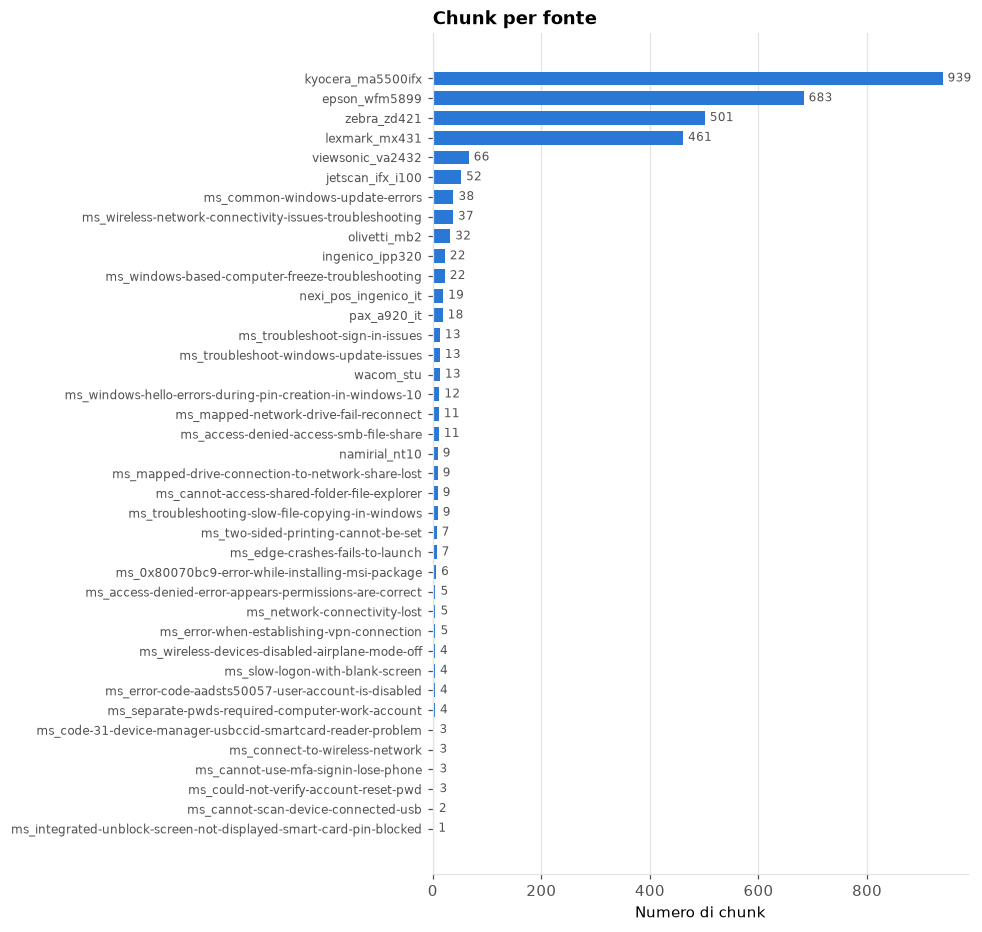

Le 3 fonti più grandi contengono il 69% dei chunk


In [23]:
per_fonte = chunk["id_fonte"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, max(4, 0.22 * len(per_fonte))))
ax.barh(per_fonte.index, per_fonte.values, color=COLORE, height=0.7)
for posizione, valore in enumerate(per_fonte.values):
    ax.text(valore + per_fonte.max() * 0.01, posizione, str(valore), va="center", fontsize=8, color=TESTO_SECONDARIO)
ax.set_title("Chunk per fonte")
ax.set_xlabel("Numero di chunk")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

quota_prime3 = per_fonte.sort_values(ascending=False).head(3).sum() / len(chunk) * 100
print(f"Le 3 fonti più grandi contengono il {quota_prime3:.0f}% dei chunk")

id_fonte,markdown,pdf,totale
categoria,,,
Access,44,0,44
Administrative rights,64,0,64
Hardware,88,2815,2903
Storage,54,0,54
totale,250,2815,3065


,chunk
periferica,
stampante di rete,2083
stampante di etichette,501
monitor,66
POS,59
selezionatrice di banconote,52
stampante di sportello,32
pad di firma,22


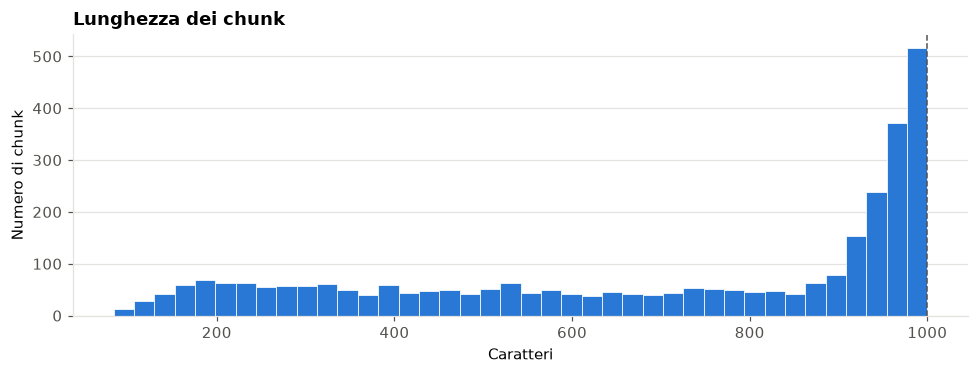

count    3065.0
mean      695.0
std       293.0
min        84.0
25%       430.0
50%       803.0
75%       962.0
max      1000.0


In [24]:
tipo_fonte = catalogo.set_index("id")["tipo"]
display(pd.crosstab(chunk["categoria"], chunk["id_fonte"].map(tipo_fonte), margins=True, margins_name="totale"))
display(chunk[chunk["periferica"] != ""]["periferica"].value_counts().to_frame("chunk"))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(chunk["caratteri"], bins=40, color=COLORE, edgecolor="white", linewidth=0.5)
ax.axvline(CHUNK_SIZE, color=TESTO_SECONDARIO, linestyle="--", linewidth=1)
ax.set_title("Lunghezza dei chunk")
ax.set_xlabel("Caratteri")
ax.set_ylabel("Numero di chunk")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
print(chunk["caratteri"].describe().round(0).to_string())

### Osservazioni (parte 7)
- **3.065 chunk** in tutto: 2.815 dai manuali (92%) e 250 dagli articoli Microsoft (8%).
- **Quattro manuali di stampanti fanno l'84% dei chunk**: Kyocera 939, Epson 683, Zebra 501, Lexmark 461 (le 3 fonti più grandi da sole il 69%). Hardware è il **95%** della knowledge base; Access (44 chunk), Storage (54) e Administrative rights (64) insieme poco più del 5%.
- **Le periferiche di sportello hanno pochi chunk**: POS 59, selezionatrice di banconote 52, stampante di sportello 32 (con le righe multilingua viste nella parte 5), pad di firma 22; in tutto il 5%. Il chatbot potrà proporre solo quello che questi manuali contengono; per il resto inoltrerà il ticket.
- **Rischio nella ricerca:** i manuali delle stampanti di rete hanno capitoli di amministrazione (login, password, rubrica, controllo degli accessi). Una richiesta di accesso o di password potrebbe trovare questi capitoli invece degli articoli Microsoft. Possibili rimedi da misurare nel notebook 06:
  - cercare solo tra i chunk della **categoria prevista dal classificatore**, quando la sicurezza è sopra la soglia;
  - chiedere all'utente di quale **periferica** si tratta, quando non è chiaro, e cercare solo nei suoi manuali;
  - aggiungere titolo e periferica al testo dei chunk prima di creare gli embeddings;
  - limitare il numero di chunk della stessa fonte nei risultati.
- **Lunghezze:** media 695 caratteri, mediana 803, minimo 84, massimo 1.000. Il picco tra 900 e 1.000 sono i pezzi tagliati al limite dalle pagine lunghe; la parte piatta da 100 a 900 sono le code delle pagine e le sezioni brevi.

## 8. Lettura esempi
Leggiamo qualche *chunk*: uno per periferica ed un paio di articoli Microsoft.
Effettuiamo due controlli: 
- **Controllo 1:** ogni manuale di periferica contiene istruzioni per risolvere problemi o solo istruzioni d'uso?
- **Controllo 2:** per alcuni problemi tipici, quali fonti contengono le parole giuste?

In [25]:
esempi = (chunk[chunk["periferica"] != ""].groupby("periferica").sample(1, random_state=RANDOM_STATE))
esempi = pd.concat([esempi, chunk[chunk["editore"] == "Microsoft"].sample(2, random_state=RANDOM_STATE)])
for riga in esempi.to_dict("records"):
    dove = f"pagina {riga['pagina']}" if pd.notna(riga["pagina"]) else f"sezione '{riga['sezione']}'"
    print(f"=== {riga['id_chunk']} · {riga['editore']} · {dove}")
    print(riga["testo"][:400], "...\n")

=== ingenico_ipp320-0001 · Ingenico · pagina 1
Introduction
Ingenico’s iPP300 secure electronic payment devices include the iPP320 and the
iPP350. Each device consists of the following:
- 2.7” graphical monochrome LCD display (iPP320)
- 2.7” TFT color QVGA display (iPP350)
- Bi-directional magnetic stripe reader
- Smart card reader
- ADA-friendly keypad
- PIN privacy shield (field-installable)
- Integrated contactless card reader. *
For detail ...

=== viewsonic_va2432-0027 · ViewSonic · pagina 25
Item Category Specifications
Audio Speaker 2 x 2W (*VA2432-mh only)
Operating
conditions
Temperature 0° C to 40° C (32° F to 104° F)
Humidity 20% to 90% (non-condensing)
Altitude 16,000 feet (5 km)
Storage
conditions
Temperature -20° C to 60° C (-4° F to 140° F)
Humidity 5% to 90% (non-condensing)
Altitude 40,000 feet (12.1 km)
Dimensions Physical (W x H x D) 540.45 x 406.05 x 185 mm (21.3” x 16”  ...

=== wacom_stu-0002 · Wacom · pagina 2
Customization

The Wacom STU Display application cons

In [26]:
# Controllo 1
PAROLE_PROBLEMI = (r"troubleshoot|problem|error|jam|not work|does not|cannot|unable|fail|clean"
                   r"|anomali|errore|problem|inceppa|non funziona|non si|impossibile|pulizia")
manuali = chunk[chunk["periferica"] != ""].copy()
manuali["parla_di_problemi"] = manuali["testo"].str.contains(PAROLE_PROBLEMI, case=False, regex=True)
copertura = manuali.groupby(["periferica", "id_fonte"]).agg(
    chunk=("testo", "size"), chunk_su_problemi=("parla_di_problemi", "sum"))
copertura["quota (%)"] = (copertura["chunk_su_problemi"] / copertura["chunk"] * 100).round(0)
display(copertura)

# Controllo 2
domande_prova = {
    "carta inceppata": r"paper jam|jammed|inceppat",
    "stampa sbiadita o assente": r"faded|light print|blank page|sbiadit",
    "cartella condivisa inaccessibile": r"shared folder|access denied|mapped drive",
    "password o account bloccato": r"password|locked out|account is disabled",
    "Wi-Fi non funziona": r"wi-?fi|wireless",
}
righe = []
for problema, schema in domande_prova.items():
    trovati = chunk[chunk["testo"].str.contains(schema, case=False, regex=True)]
    righe.append({"problema": problema, "chunk trovati": len(trovati),
                  "fonti principali": ", ".join(trovati["id_fonte"].value_counts().head(3).index)})
display(pd.DataFrame(righe).set_index("problema"))

chunk  chunk_su_problemi  \
periferica                  id_fonte                                         
POS                         ingenico_ipp320          22                  5   
                            nexi_pos_ingenico_it     19                  5   
                            pax_a920_it              18                  0   
monitor                     viewsonic_va2432         66                 19   
pad di firma                namirial_nt10             9                  2   
                            wacom_stu                13                  2   
selezionatrice di banconote jetscan_ifx_i100         52                 25   
stampante di etichette      zebra_zd421             501                175   
stampante di rete           epson_wfm5899           683                265   
                            kyocera_ma5500ifx       939                229   
                            lexmark_mx431           461                183   
stampante di sportello      olivetti_mb2             32                  8   

                                                  quota (%)  
periferica                  id_fonte                         
POS                         ingenico_ipp320            23.0  
                            nexi_pos_ingenico_it       26.0  
                            pax_a920_it                 0.0  
monitor                     viewsonic_va2432           29.0  
pad di firma                namirial_nt10              22.0  
                            wacom_stu                  15.0  
selezionatrice di banconote jetscan_ifx_i100           48.0  
stampante di etichette      zebra_zd421                35.0  
stampante di rete           epson_wfm5899              39.0  
                            kyocera_ma5500ifx          24.0  
                            lexmark_mx431              40.0  
stampante di sportello      olivetti_mb2               25.0

,chunk trovati,fonti principali
problema,,
carta inceppata,65,"kyocera_ma5500ifx, lexmark_mx431, epson_wfm5899"
stampa sbiadita o assente,36,"kyocera_ma5500ifx, epson_wfm5899, lexmark_mx431"
cartella condivisa inaccessibile,54,"kyocera_ma5500ifx, ms_access-denied-access-smb-file-share, ms_troubleshooting-slow-file-copying-in-windows"
password o account bloccato,300,"kyocera_ma5500ifx, epson_wfm5899, lexmark_mx431"
Wi-Fi non funziona,291,"kyocera_ma5500ifx, epson_wfm5899, zebra_zd421"


### Osservazioni (parte 8)
**Chunk letti**
- Molti chunk **non dicono di quale dispositivo parlano** e letti da soli potrebbero essere di qualsiasi stampante o monitor. Altri si, grazie alle intestazioni rimaste. Nel notebook 06 aggiungerò **titolo e periferica** al testo da cui creare gli embeddings.
- Diversi chunk non sono istruzioni per risolvere problemi: specifiche tecniche, amministrazione, non indicazioni da fornire all'utente di sportello. Il prompt dovrà chiedere all'LLM di proporre solo passaggi che l'utente può fare da solo.
- Leggere gli esempi ha portato a tre correzioni della pulizia: i simboli dei font (es. pallini degli elenchi nel manuale Ingenico), le sezioni Microsoft fatte solo di link e le sezioni "Data collection".

**Istruzioni per risolvere problemi (ricerca per parole, misura approssimativa)**
- La **guida PAX non ne contiene** (0 chunk su 18): è solo una guida d'uso. In tutto i **POS** hanno 10 chunk sui problemi, i **pad di firma** 4, la **stampante di sportello** 8: su questi dispositivi il chatbot avrà poco da proporre e inoltrerà presto il ticket.
- La **JetScan** è la più completa (48%); tra le stampanti il manuale **Kyocera** ha la quota più bassa (24%) perché gran parte del manuale è amministrazione.

**Problemi di prova**
- Per **password o account bloccato** (300 chunk) e **Wi-Fi** (291) le prime tre fonti sono **manuali di stampanti**; per **cartella condivisa** il primo è Kyocera (capitolo sull'invio delle scansioni a cartelle condivise). Gli articoli Microsoft, che sono le fonti giuste, restano quindi in secondo piano.
- È una ricerca per parole, più grezza della ricerca semantica che faremo nel notebook 06, ma conferma che la ricerca dovrà usare la **categoria prevista dal classificatore** e la **periferica** indicata dall'utente.

## 9. Salvataggio
Salviamo i chunk in formato **JSON Lines** (`.jsonl`): un oggetto JSON per riga.

**Perché in formato JSONL e non CSV?** I chunk contengono a capo, virgole e virgolette che in un CSV vanno gestiti con attenzione mentre, in JSONL, ogni chunk è un oggetto completo con i suoi metadati e si può leggere anche una riga alla volta.

In [27]:
colonne = ["id_chunk", "id_fonte", "titolo", "editore", "categoria", "periferica", "lingua",
           "url", "licenza", "pagina", "sezione", "testo"]
with open(CHUNKS_PATH, "w", encoding="utf-8") as f:
    for record in chunk[colonne].to_dict("records"):
        record["pagina"] = None if pd.isna(record["pagina"]) else int(record["pagina"])
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

riepilogo = catalogo[["id", "editore", "tipo", "categoria", "periferica"]].set_index("id")
riepilogo["unita_estratte"] = unita.groupby("id_fonte").size()
riepilogo["unita_tenute"] = da_dividere.groupby("id_fonte").size()
riepilogo["chunk"] = chunk.groupby("id_fonte").size()
riepilogo = riepilogo.fillna(0).astype({"unita_estratte": int, "unita_tenute": int, "chunk": int})
riepilogo.to_csv(RIEPILOGO_PATH)

print(f"Salvati {len(chunk)} chunk in {CHUNKS_PATH.resolve()} ({CHUNKS_PATH.stat().st_size / 1e6:.1f} MB)")

Salvati 3065 chunk in C:\Users\logic\Desktop\PROGRAMMAZIONE\GitHub\Capstone_Project\knowledge_base\chunks.jsonl (3.5 MB)


In [28]:
# Controllo: rileggiamo il file come farà il notebook 06
with open(CHUNKS_PATH, encoding="utf-8") as f:
    riletti = [json.loads(riga) for riga in f]
assert len(riletti) == len(chunk), "Il numero di chunk riletti non coincide"
assert len({c["id_chunk"] for c in riletti}) == len(riletti), "id_chunk non univoci"
print("OK:", len(riletti), "chunk riletti. Esempio di metadati:")
print({k: v for k, v in riletti[0].items() if k != "testo"})

OK: 3065 chunk riletti. Esempio di metadati:
{'id_chunk': 'epson_wfm5899-0001', 'id_fonte': 'epson_wfm5899', 'titolo': "WF-M5899 User's Guide", 'editore': 'Epson', 'categoria': 'Hardware', 'periferica': 'stampante di rete', 'lingua': 'en', 'url': 'https://files.support.epson.com/docid/cpd6/cpd63499.pdf', 'licenza': 'copyright del produttore (non ridistribuito)', 'pagina': 17, 'sezione': ''}


## 10. Riepilogo
| Aspetto | Valore / osservazione |
|---|---|
| Fonti nel catalogo (articoli Microsoft / manuali) | **39** (27 / 12) |
| Fonti scaricate automaticamente / recuperate a mano / mancanti | 38 in automatico (JetScan dopo aver corretto il link, che dava 404) / 1 a mano (Kyocera) / **0 mancanti** |
| Pagine PDF estratte / tenute (scartate come indice / perché corte) | **1.770 / 1.654** (48 / 68) |
| Righe tolte perché in altre lingue (e da quali manuali) | **89**: Olivetti 70, Lexmark 11, Kyocera 8 (avvisi legali); nessuna riga giusta tolta |
| Sezioni Markdown tenute | **184 su 206** (tolte 6 fatte solo di link, 5 "Data collection", 11 troppo corte) |
| Problemi di pulizia trovati e risolti | PDF cifrato (`pypdf[crypto]`); indici in formato capitolo-pagina; piè di pagina numerati (confronto per "forma"); manuale con 5 lingue sulla stessa pagina (filtro per riga); parole comuni a più lingue nelle liste; simboli dei font; link con parentesi; segnaposto `<...>` conservati |
| Chunk finali (frammenti e duplicati tolti) | **3.065** (15 frammenti, 4 duplicati); media 695 caratteri, mediana 803 |
| Fonti che dominano la knowledge base | 4 manuali di stampanti = **84%** dei chunk (Kyocera 939, Epson 683, Zebra 501, Lexmark 461); Hardware = **95%** |
| Periferiche con pochi chunk | pad di firma 22, stampante di sportello 32, selezionatrice 52, POS 59 (in tutto il 5%) |
| Manuali con poche istruzioni per risolvere problemi | PAX (0), Wacom (2), Namirial (2): POS 10 chunk sui problemi, pad di firma 4, Olivetti 8 |
| Limiti noti | Righe brevi in altre lingue nell'Olivetti; contenuti per amministratori nei manuali grandi e in alcuni articoli Microsoft; nessun articolo su Outlook |